source                 ground truth  true logit           GRU        TabPFN
pattern key number                                                         
P1      cell              1.5 (0.0)   1.5 (0.0)    1.1 (0.19)   1.36 (0.23)
        MAE truth != 0            -   0.0 (0.0)    0.4 (0.19)   0.18 (0.17)
        MAE truth = 0             -   0.0 (0.0)     0.0 (0.0)    0.01 (0.0)
P2      cell              0.5 (0.0)   0.5 (0.0)   0.63 (0.09)    0.51 (0.0)
        MAE truth != 0            -  0.02 (0.0)   0.28 (0.06)    0.2 (0.02)
        MAE truth = 0             -   0.0 (0.0)    0.01 (0.0)    0.01 (0.0)
P3      MAE truth != 0            -   0.0 (0.0)   0.29 (0.06)   0.23 (0.15)
        MAE truth = 0             -   0.0 (0.0)    0.02 (0.0)    0.01 (0.0)
        visit 8           1.5 (0.0)   1.5 (0.0)    1.33 (0.6)   1.39 (0.35)
        visit 10         -1.5 (0.0)  -1.5 (0.0)  -1.53 (0.13)  -1.29 (0.15)
P4      MAE truth != 0            -  0.01 (0.0)   0.16 (0.15)   0.23 (0.15)
        MAE truth = 0             -   0.0 (0.0)    0.01 (0.0)    0.01 (0.0)
        1 occ.            1.5 (0.0)   1.5 (0.0)   1.28 (0.29)   1.28 (0.39)
        2 occ.           0.75 (0.0)  0.75 (0.0)    0.8 (0.05)   0.69 (0.03)
        3 occ.            0.5 (0.0)   0.5 (0.0)   0.57 (0.08)    0.4 (0.03)
P5      MAE truth != 0            -   0.0 (0.0)    0.83 (0.3)   0.71 (0.05)
        MAE truth = 0             -   0.0 (0.0)   0.01 (0.01)    0.01 (0.0)
        share code 2      0.0 (0.0)  -0.0 (0.0)   0.47 (0.02)    0.5 (0.01)

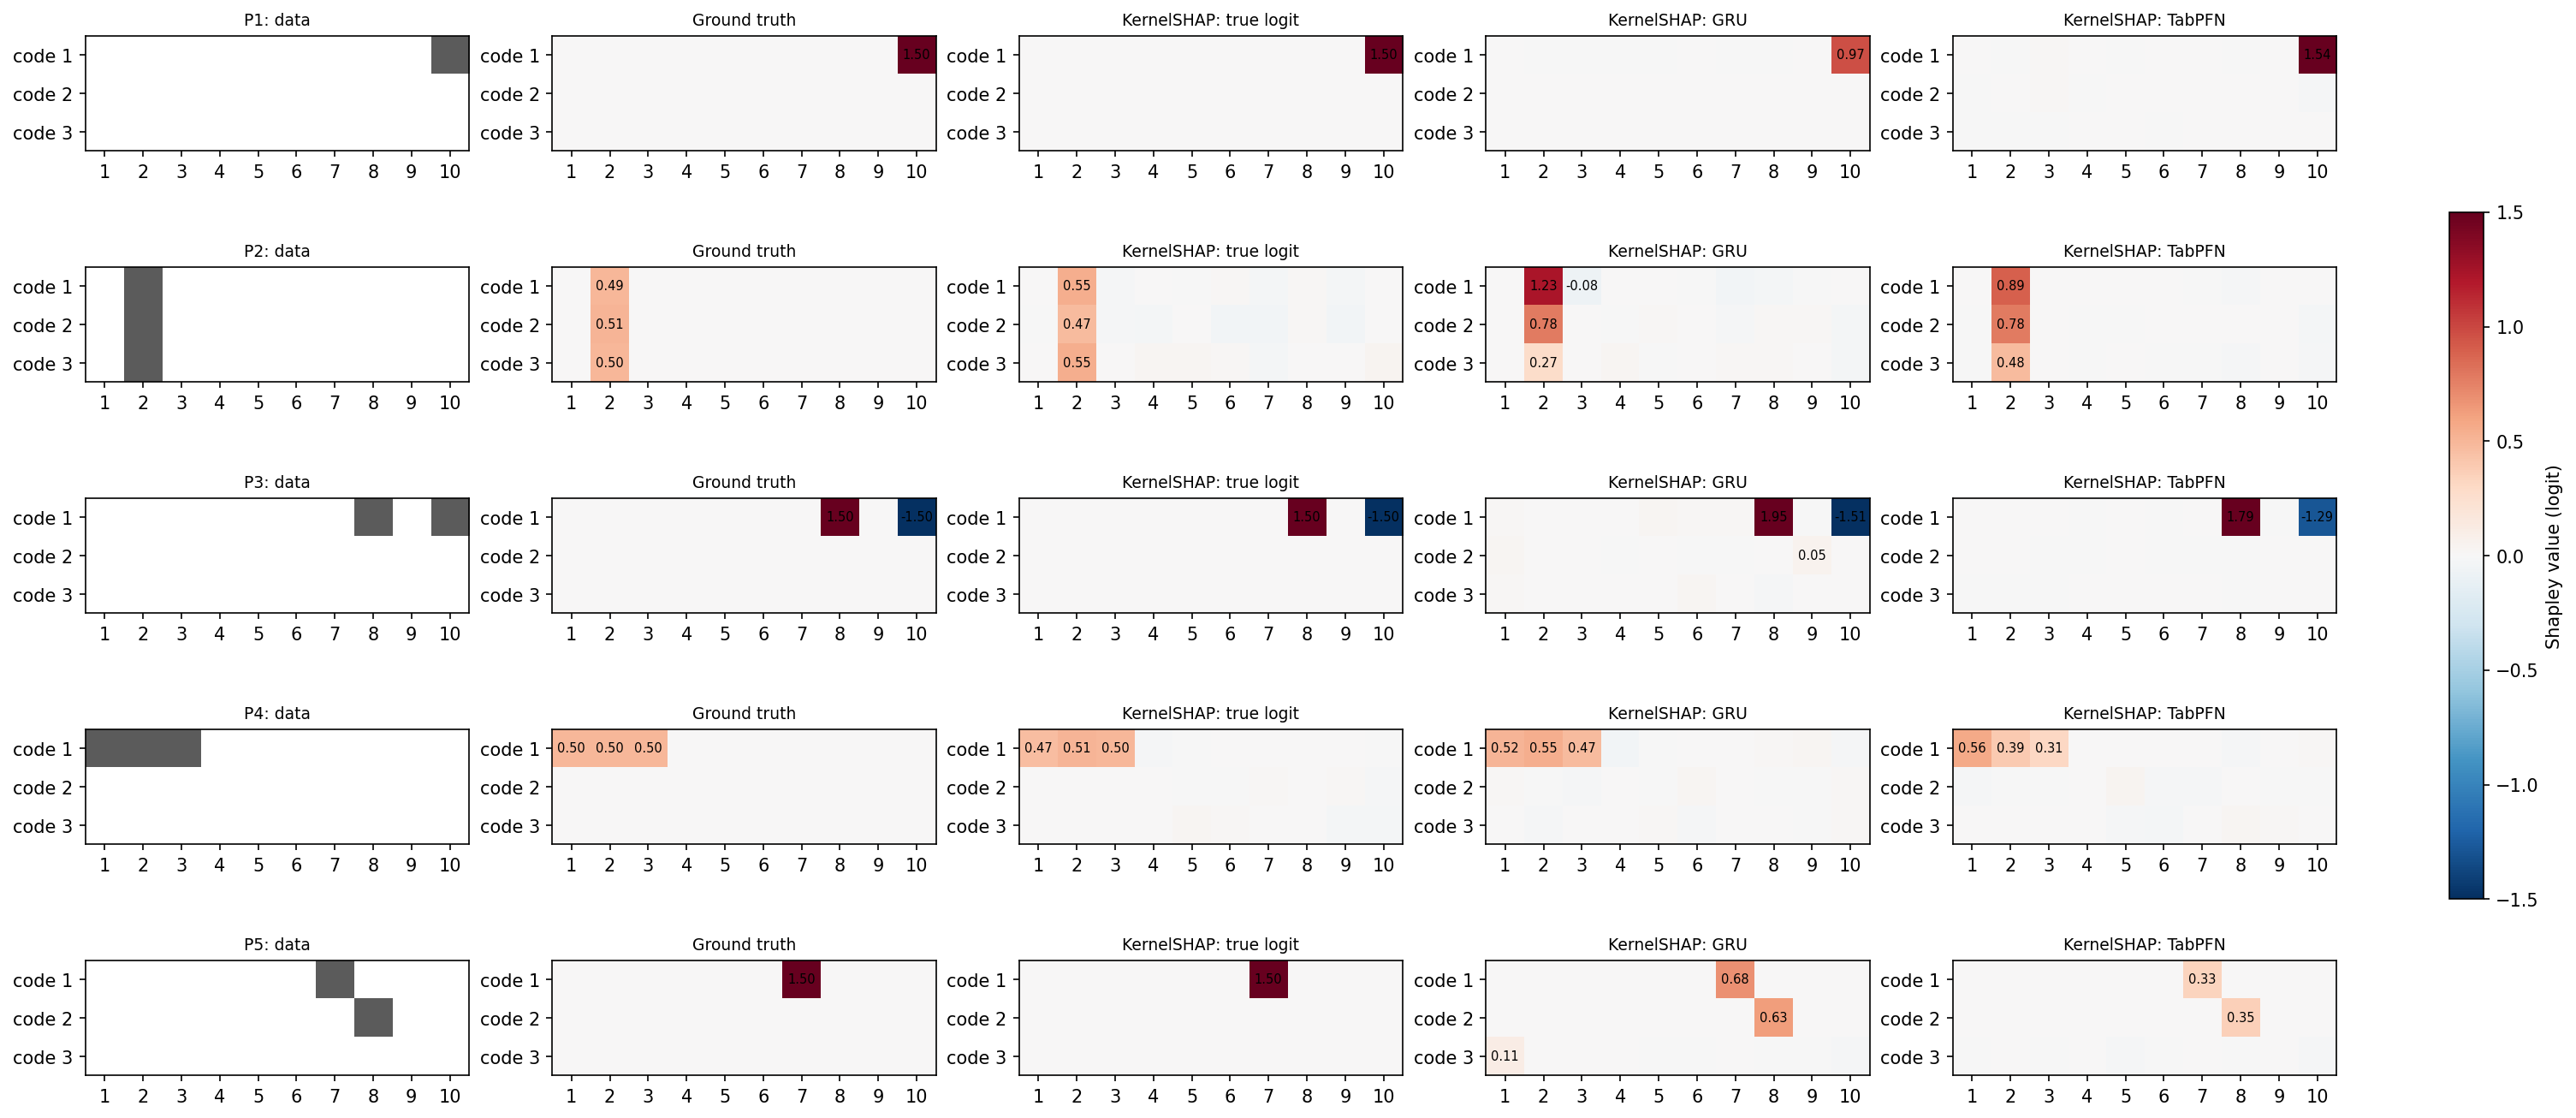

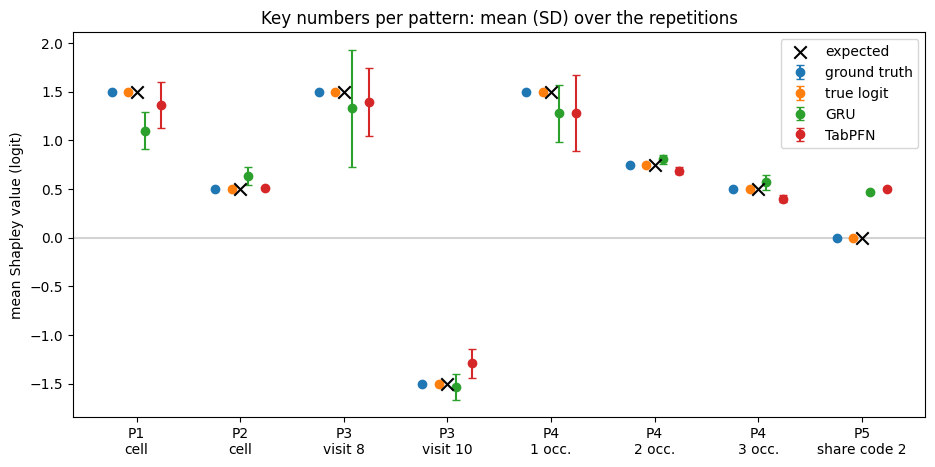

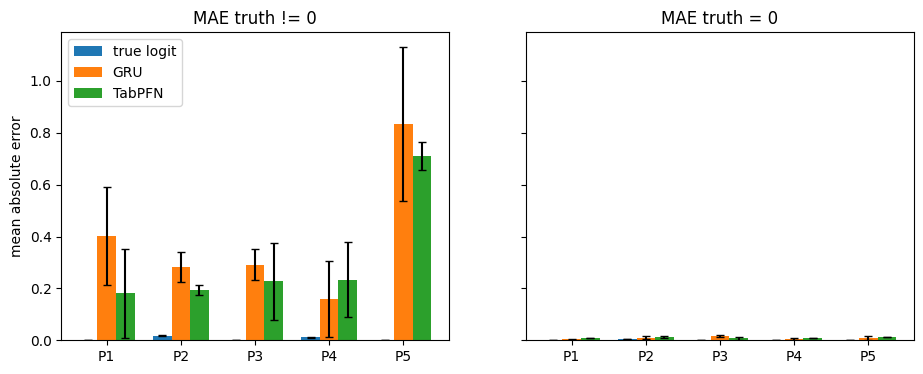

source,GRU,TabPFN,ground truth,true logit
rep,,,,
0,0.48,0.51,0.0,-0.0
1,0.46,0.49,0.0,0.0


In [2]:
#.......................................................................................
# Load the results
#.......................................................................................

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

results = pd.read_csv("results_all_patterns.csv")
beta = 1.5

#.......................................................................................
# 1. Table: mean (SD) over the repetitions
#.......................................................................................

means = results.pivot_table(index=["pattern", "key number"], columns="source",
                            values="value", aggfunc="mean", sort=False)
sds = results.pivot_table(index=["pattern", "key number"], columns="source",
                          values="value", aggfunc="std", sort=False)

table = means.round(2).astype(str) + " (" + sds.round(2).astype(str) + ")"
table = table[["ground truth", "true logit", "GRU", "TabPFN"]].replace("nan (nan)", "-")
display(table)

#.......................................................................................
# 2. Heatmaps of the example persons (last repetition)
#.......................................................................................

display(Image("heatmaps_all_patterns.png"))

#.......................................................................................
# 3. Plot: key numbers vs expected values
# One point per model (mean over the repetitions), bars = SD, black x = expected value
#.......................................................................................

key_numbers = [("P1", "cell"), ("P2", "cell"), ("P3", "visit 8"), ("P3", "visit 10"),
               ("P4", "1 occ."), ("P4", "2 occ."), ("P4", "3 occ."), ("P5", "share code 2")]
expected = [beta, beta / 3, beta, -beta, beta, beta / 2, beta / 3, 0]
labels = [f"{p}\n{k}" for p, k in key_numbers]
x = np.arange(len(key_numbers))

fig, ax = plt.subplots(figsize=(11, 5))
ax.axhline(0, color="lightgrey")
ax.scatter(x, expected, marker="x", s=80, color="black", label="expected", zorder=3)

for i, source in enumerate(["ground truth", "true logit", "GRU", "TabPFN"]):
    m = [means.loc[k, source] for k in key_numbers]
    s = [sds.loc[k, source] for k in key_numbers]
    ax.errorbar(x - 0.24 + 0.16 * i, m, yerr=s, fmt="o", capsize=3, label=source)

ax.set_xticks(x, labels)
ax.set_ylabel("mean Shapley value (logit)")
ax.set_title("Key numbers per pattern: mean (SD) over the repetitions")
ax.legend()
plt.savefig("key_numbers.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 4. Plot: errors against the ground truth (KernelSHAP only)
# Left: on the pattern cells (truth != 0); right: spurious credit (truth = 0)
#.......................................................................................

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
patterns = ["P1", "P2", "P3", "P4", "P5"]
x = np.arange(len(patterns))

for ax, key in zip(axes, ["MAE truth != 0", "MAE truth = 0"]):
    for i, source in enumerate(["true logit", "GRU", "TabPFN"]):
        m = [means.loc[(p, key), source] for p in patterns]
        s = [sds.loc[(p, key), source] for p in patterns]
        ax.bar(x - 0.25 + 0.25 * i, m, width=0.25, yerr=s, capsize=3, label=source)
    ax.set_xticks(x, patterns)
    ax.set_title(key)
axes[0].set_ylabel("mean absolute error")
axes[0].legend()
plt.savefig("errors.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 5. Optional: every repetition separately, e.g. how stable P5 is
#.......................................................................................

p5 = results[(results["pattern"] == "P5") & (results["key number"] == "share code 2")]
display(p5.pivot(index="rep", columns="source", values="value").round(2))